In [2]:

import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

# 1. Load dataset
url = "Data/Main_Clean.csv"
df = pd.read_csv(url)
# df.head()

# 2. Select features
features = [
    "AnnualIncome",
    "AnnualPurchaseAmount",
    "PurchaseFrequency"
]

X = df[features].copy()

# 3. Train-test split
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

# 4. Create complete K-Means pipeline
kmeans_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

# 5. Train model
kmeans_pipeline.fit(X_train)

print("Model Training Completed!")

# 6. Predict clusters
train_clusters = kmeans_pipeline.predict(X_train)
test_clusters = kmeans_pipeline.predict(X_test)

# 7. Check cluster distribution
print("\nTraining Cluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())

# 8. Check inertia
print("\nInertia:", kmeans_pipeline.named_steps["kmeans"].inertia_)

# 9. Save complete pipeline
# joblib.dump(kmeans_pipeline, "kmeans_model.pkl")

Model Training Completed!

Training Cluster Distribution:
0     33558
1    144842
2    220800
Name: count, dtype: int64

Inertia: 518648.1720225612


In [ ]:
# Load trained model
kmeans_model = joblib.load("kmeans_model.pkl")

# Take customer input
income = float(input("Enter Annual Income: "))
spending = float(input("Enter Annual Purchase Amount: "))
frequency = int(input("Enter Purchase Frequency: "))

# Create input DataFrame
new_customer = pd.DataFrame([{
    "AnnualIncome": income,
    "AnnualPurchaseAmount": spending,
    "PurchaseFrequency": frequency
}])

# Predict cluster
cluster = kmeans_model.predict(new_customer)[0]

In [3]:
# Get cluster labels for training data
train_result = X_train.copy()
train_result["Cluster"] = train_clusters

# Calculate average values for each cluster
cluster_summary = train_result.groupby("Cluster")[features].mean().round(2)

print(cluster_summary)

         AnnualIncome  AnnualPurchaseAmount  PurchaseFrequency
Cluster                                                       
0           124184.93              34714.11              19.41
1            83023.86              16004.09              10.94
2            48551.79               7534.09               5.40


In [4]:
cluster_names = {
    0: "Premium",
    1: "Regular",
    2: "Budget"
}

train_result = X_train.copy()
train_result["Cluster"] = train_clusters
train_result["CustomerSegment"] = train_result["Cluster"].map(cluster_names)

In [5]:
segment_distribution = train_result["CustomerSegment"].value_counts()

segment_summary = pd.DataFrame({
    "CustomerCount": segment_distribution,
    "Percentage": (segment_distribution / len(train_result) * 100).round(2)
})

print(segment_summary)

                 CustomerCount  Percentage
CustomerSegment                           
Budget                  220800       55.31
Regular                 144842       36.28
Premium                  33558        8.41


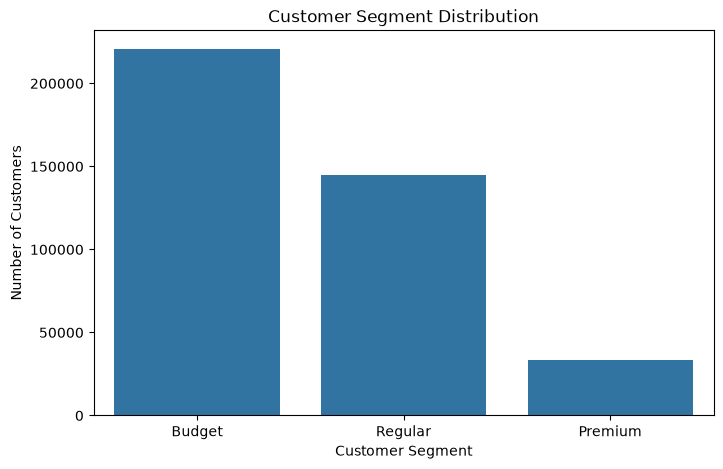

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_summary.index,
    y=segment_summary["CustomerCount"]
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
from sklearn.metrics import silhouette_score

X_train_scaled = kmeans_pipeline.named_steps["scaler"].transform(
    kmeans_pipeline.named_steps["imputer"].transform(X_train)
)

score = silhouette_score(
    X_train_scaled,
    train_clusters,
    sample_size=10000,
    random_state=42
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.3659


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

X_scaled = kmeans_pipeline.named_steps["scaler"].transform(
    kmeans_pipeline.named_steps["imputer"].transform(X_train)
)

inertias = []
silhouette_scores = []

for k in range(2, 9):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K={k}, Inertia={km.inertia_:.2f}, Silhouette={score:.4f}")

K=2, Inertia=675426.89, Silhouette=0.4852
K=3, Inertia=518648.17, Silhouette=0.3659
K=4, Inertia=429174.68, Silhouette=0.3729
K=5, Inertia=370961.08, Silhouette=0.3074
K=6, Inertia=324119.79, Silhouette=0.3113
K=7, Inertia=294672.12, Silhouette=0.2908
K=8, Inertia=271043.42, Silhouette=0.2845


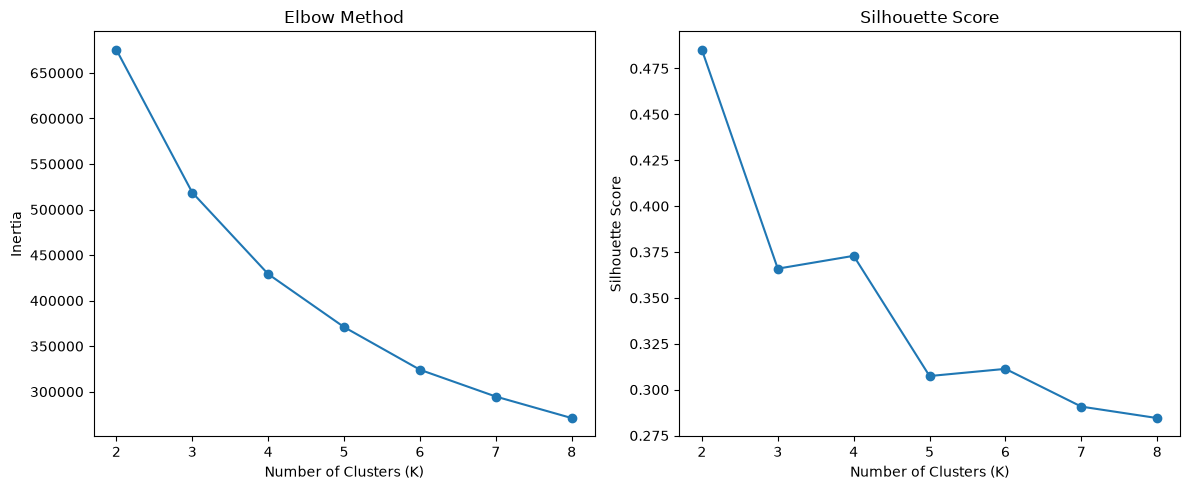

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(2, 9), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(range(2, 9), silhouette_scores, marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()